<a href="https://colab.research.google.com/github/hhanoudi/AIHC-5010-Winter-2026hhs/blob/main/HWRK5Sept12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

problem 1

In [ ]:
!pip install -q wfdb
from google.colab import drive
import wfdb
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define the path to the dataset
db_path = '/content/drive/MyDrive/AIHC5020/timeseries/ecg_wfdb'

if os.path.exists(db_path):
    print(f"Successfully accessed: {db_path}")
    files = os.listdir(db_path)
    print(f"Files in directory: {files}")
else:
    print(f"Path not found: {db_path}. Please verify the folder exists in your Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully accessed: /content/drive/MyDrive/AIHC5020/timeseries/ecg_wfdb
Files in directory: ['100.atr', '100.dat', '100.hea', '101.hea', '101.atr', '101.dat', '102.dat', '102.hea', '103.hea', '103.atr', '103.dat', '104.hea', '104.dat', '104.atr', '105.hea', '105.dat', '105.atr', '106.atr', '106.dat', '106.hea', '107.dat', '107.atr', '107.hea', '108.at_', '108.hea', '109.atr', '109.hea', '111.atr', '111.hea', '112.hea', '112.atr', '113.hea', '113.atr', '114.hea', '114.atr', '115.hea', '115.atr', '116.hea', '116.atr', '117.hea', '117.at_', '118.atr', '118.dat', '118.hea', '119.dat', '119.hea', '119.at_', '121.atr', '121.hea', '122.hea', '122.atr', '123.atr', '123.hea', '124.atr', '124.hea', '200.dat', '200.atr', '200.hea', '201.atr', '201.dat', '201.hea', '202.hea', '202.dat', '202.atr', '203.hea', '203.at_', '203.dat', '205.hea', '205.dat', '205.atr', '207.

Displaying record: 100


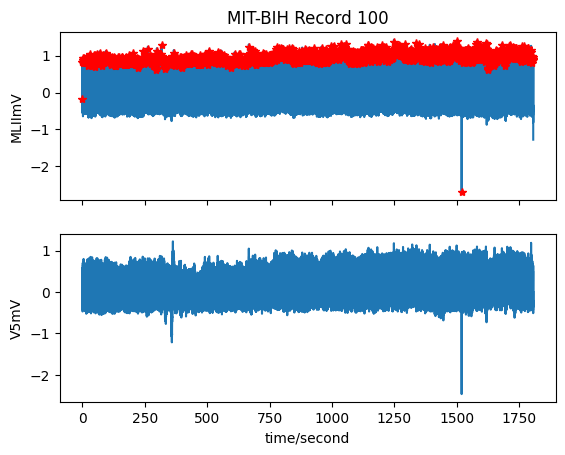

In [ ]:
import wfdb
import os
import matplotlib.pyplot as plt

# Set the record name (excluding extension)
record_name = os.path.join(db_path, '100')

try:
    # Read the WFDB record and annotations
    record = wfdb.rdrecord(record_name)
    annotation = wfdb.rdann(record_name, 'atr')

    # Plot the record with annotations
    print(f"Displaying record: {record.record_name}")
    wfdb.plot_wfdb(record=record, annotation=annotation,
                   title='MIT-BIH Record 100',
                   time_units='seconds')
except Exception as e:
    print(f"Error reading record: {e}")

In [ ]:
# Calculate the cutoff sample index as an integer
max_duration = 15
sampling_frequency = 360
cutoff_sample_index = int(max_duration * sampling_frequency)

print(f"Cutoff sample index: {cutoff_sample_index}")

Cutoff sample index: 5400


In [ ]:
import pandas as pd
import wfdb
import os

# 1. Ensure we have the record and annotations for 101
record_101 = wfdb.rdrecord(os.path.join(db_path, '101'))
annotation_101 = wfdb.rdann(os.path.join(db_path, '101'), 'atr')

# 2. Create the Signal DataFrame (ecg_df)
ecg_df = pd.DataFrame(
    data=record_101.p_signal[:cutoff_sample_index, :],
    columns=record_101.sig_name
)

# 3. Create the Annotation Log DataFrame (filtered)
annotation_log_df = pd.DataFrame({
    'annotation_index': annotation_101.sample,
    'annotation_text': annotation_101.symbol
})
annotation_log_df = annotation_log_df[annotation_log_df['annotation_index'] < cutoff_sample_index].reset_index(drop=True)

# 4. Create the final tuple
sample_rate = record_101.fs
ecg_data_bundle = (ecg_df, annotation_log_df, sample_rate)

# Verification
print(f"Tuple created successfully.")
print(f"Signal samples: {len(ecg_data_bundle[0])}")
print(f"Annotation count: {len(ecg_data_bundle[1])}")
print(f"Sample Rate: {ecg_data_bundle[2]} Hz")

Tuple created successfully.
Signal samples: 5400
Annotation count: 18
Sample Rate: 360 Hz


In [ ]:
import wfdb
import pandas as pd
import os

# Define record 100 path and 10s cutoff (10 * 360 = 3600)
rec100_path = os.path.join(db_path, '100')
cutoff_10s = 10 * 360

# Load record 100
record_100 = wfdb.rdrecord(rec100_path)

# Create DataFrame for first 10 seconds
ecg_df_100 = pd.DataFrame(
    data=record_100.p_signal[:cutoff_10s, :],
    columns=record_100.sig_name
)

# Display the last 5 rows
display(ecg_df_100.tail(5))

,MLII,V5
3595,-0.385,-0.285
3596,-0.395,-0.285
3597,-0.390,-0.295
3598,-0.400,-0.290
3599,-0.405,-0.285


In [ ]:
import pandas as pd

# Create a DataFrame from the filtered annotations for Record 100
annotation_log_100 = pd.DataFrame({
    'annotation_index': filtered_indices,
    'annotation_symbol': filtered_symbols
})

# Display the last 5 rows
annotation_log_100.tail(5)

,annotation_index,annotation_symbol
9,2402,N
10,2706,N
11,2998,N
12,3282,N
13,3560,N


In [ ]:
import wfdb
import pandas as pd
import os

# Parameters
rec_id = '101'
max_duration = 15
fs = 360
cutoff_101 = max_duration * fs
path_101 = os.path.join(db_path, rec_id)

# Load record and annotations
record_101 = wfdb.rdrecord(path_101)
annotation_101 = wfdb.rdann(path_101, 'atr')

# Create Signal DataFrame
ecg_df_101 = pd.DataFrame(
    data=record_101.p_signal[:cutoff_101, :],
    columns=record_101.sig_name
)

# Create Annotation Log DataFrame
mask_101 = annotation_101.sample < cutoff_101
annotation_log_101 = pd.DataFrame({
    'annotation_index': annotation_101.sample[mask_101],
    'annotation_symbol': [annotation_101.symbol[i] for i, m in enumerate(mask_101) if m]
})

print(f"Record {rec_id} processed for {max_duration} seconds.")
display(ecg_df_101.tail(5))
display(annotation_log_101.tail(5))

Record 101 processed for 15 seconds.


,MLII,V1
5395,-0.275,-0.035
5396,-0.250,-0.015
5397,-0.245,-0.005
5398,-0.245,0.005
5399,-0.250,0.000


,annotation_index,annotation_symbol
13,3960,N
14,4283,N
15,4609,N
16,4928,N
17,5241,N


problem 2

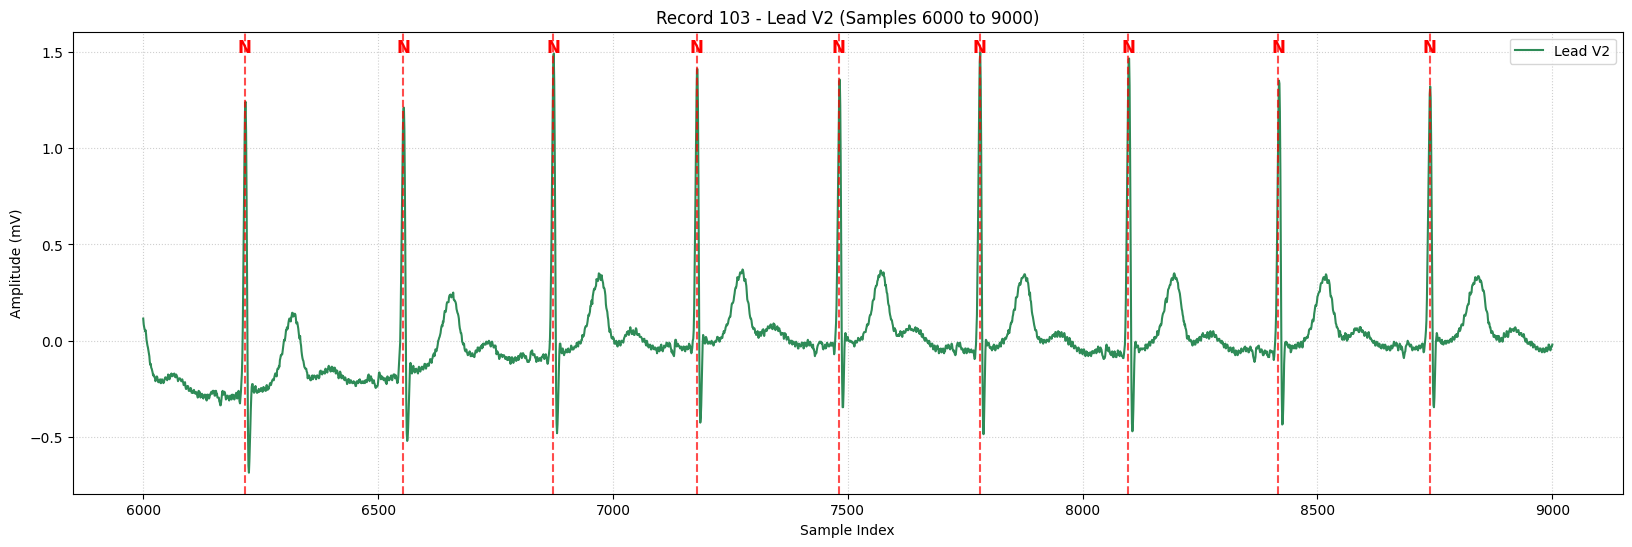

In [ ]:
import wfdb
import pandas as pd
import matplotlib.pyplot as plt
import os

# Parameters
rec_id = '103'
start_idx = 6000
end_idx = 9000
channel_name = 'V2'
rec_path = os.path.join(db_path, rec_id)

# 1. Load record and annotations
record_103 = wfdb.rdrecord(rec_path)
annotation_103 = wfdb.rdann(rec_path, 'atr')

# 2. Create the full ecg_df for record 103
ecg_df_103 = pd.DataFrame(
    data=record_103.p_signal,
    columns=record_103.sig_name
)

# 3. Create a slice using .loc
# Note: since the index is integer-based starting from 0, .loc[start:end] is inclusive of end
ecg_slice = ecg_df_103.loc[start_idx:end_idx, [channel_name]]

# 4. Filter annotations within the range
mask = (annotation_103.sample >= start_idx) & (annotation_103.sample <= end_idx)
slice_ann_indices = annotation_103.sample[mask]
slice_ann_symbols = [annotation_103.symbol[i] for i, m in enumerate(mask) if m]

# 5. Visualize the waveform
plt.figure(figsize=(20, 6))
plt.plot(ecg_slice.index, ecg_slice[channel_name], color='seagreen', label=f'Lead {channel_name}')

# Draw vertical dashed lines for annotations
for idx, sym in zip(slice_ann_indices, slice_ann_symbols):
    plt.axvline(x=idx, color='red', linestyle='--', alpha=0.7)
    plt.text(idx, ecg_slice[channel_name].max(), sym, color='red', fontsize=12, fontweight='bold', ha='center')

plt.xlabel('Sample Index')
plt.ylabel('Amplitude (mV)')
plt.title(f'Record {rec_id} - Lead {channel_name} (Samples {start_idx} to {end_idx})')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

problem 3

In [ ]:
import wfdb
import pandas as pd
import os
import numpy as np

def create_segment_table(record_number, max_duration, wfdb_root, segment_duration):
    # 1. Load the record
    rec_path = os.path.join(wfdb_root, str(record_number))
    record = wfdb.rdrecord(rec_path)

    fs = record.fs
    max_samples = int(max_duration * fs)
    segment_samples = int(segment_duration * fs)

    # Slice signal to max_duration
    signal = record.p_signal[:max_samples, :]
    n_total_samples = signal.shape[0]
    channels = record.sig_name

    rows = []

    # 2. Iterate through segments
    # We calculate how many full segments fit into the signal
    num_segments = n_total_samples // segment_samples

    for seg_idx in range(num_segments):
        start_ptr = seg_idx * segment_samples
        end_ptr = start_ptr + segment_samples

        # 3. Iterate through each channel per segment
        for ch_idx, ch_name in enumerate(channels):
            segment_data = signal[start_ptr:end_ptr, ch_idx]

            row = {
                'record_number': record_number,
                'segment_index': seg_idx,
                'sample_rate': fs,
                'n_samples': len(segment_data),
                'channel_name': ch_name,
                'segment_start_index': start_ptr,
                'segment': segment_data.tolist() # Stored as list for the DataFrame column
            }
            rows.append(row)

    return pd.DataFrame(rows)

# Execution for record 100, 30s max duration, 4s segments
segment_df_100 = create_segment_table(
    record_number='100',
    max_duration=30,
    wfdb_root=db_path,
    segment_duration=4
)

# Display the first five rows
segment_df_100.head(5)

,record_number,segment_index,sample_rate,n_samples,channel_name,segment_start_index,segment
0,100,0,360,1440,MLII,0,"[-0.145, -0.145, -0.145, -0.145, -0.145, -0.14..."
1,100,0,360,1440,V5,0,"[-0.065, -0.065, -0.065, -0.065, -0.065, -0.06..."
2,100,1,360,1440,MLII,1440,"[-0.27, -0.255, -0.26, -0.265, -0.26, -0.25, -..."
3,100,1,360,1440,V5,1440,"[-0.26, -0.255, -0.25, -0.255, -0.25, -0.24, -..."
4,100,2,360,1440,MLII,2880,"[-0.32, -0.315, -0.33, -0.34, -0.34, -0.35, -0..."


In [ ]:
# Challenge Case: Apply the function to Record 102
segment_df_102 = create_segment_table(
    record_number='102',
    max_duration=30,
    wfdb_root=db_path,
    segment_duration=4
)

# Display the first five rows
segment_df_102.head(5)

,record_number,segment_index,sample_rate,n_samples,channel_name,segment_start_index,segment
0,102,0,360,1440,V5,0,"[-0.2, -0.2, -0.2, -0.2, -0.2, -0.2, -0.2, -0...."
1,102,0,360,1440,V2,0,"[0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.0..."
2,102,1,360,1440,V5,1440,"[-0.15, -0.155, -0.15, -0.165, -0.175, -0.165,..."
3,102,1,360,1440,V2,1440,"[0.705, 0.635, 0.565, 0.505, 0.465, 0.43, 0.38..."
4,102,2,360,1440,V5,2880,"[-0.225, -0.215, -0.205, -0.21, -0.21, -0.2, -..."


problem 4


In [ ]:
import os

# Define the path to the DICOM dataset
dicom_path = '/content/drive/MyDrive/AIHC5020/dicom/tcia/LIDC-IDRI'

if os.path.exists(dicom_path):
    print(f"Successfully accessed: {dicom_path}")
    # List the first few items to avoid cluttering the output if there are many folders
    contents = os.listdir(dicom_path)
    print(f"Found {len(contents)} items in directory.")
    print("Preview of contents:", contents[:10])
else:
    print(f"Path not found: {dicom_path}. Please check if the folder exists or if Drive is mounted correctly.")

Successfully accessed: /content/drive/MyDrive/AIHC5020/dicom/tcia/LIDC-IDRI
Found 8 items in directory.
Preview of contents: ['LICENSE', '.DS_Store', 'LIDC-IDRI-0006', 'LIDC-IDRI-0004', 'LIDC-IDRI-0003', 'LIDC-IDRI-0005', 'LIDC-IDRI-0002', 'LIDC-IDRI-0001']


In [ ]:
!pip install -q pydicom
import os
import pydicom
import pandas as pd
from pathlib import Path

def create_dicom_manifest(root_dir):
    manifest_data = []
    root = Path(root_dir)

    # Walk through all directories in the root_dir
    for subdir, dirs, files in os.walk(root):
        dcm_files = [f for f in files if f.lower().endswith('.dcm')]

        # If the folder contains DICOM files, it's a series folder
        if dcm_files:
            sample_dcm_path = os.path.join(subdir, dcm_files[0])

            try:
                ds = pydicom.dcmread(sample_dcm_path, stop_before_pixels=True)

                row = {
                    'patient_id': ds.get('PatientID', 'N/A'),
                    'study_date': ds.get('StudyDate', 'N/A'),
                    'modality': ds.get('Modality', 'N/A'),
                    'series_description': ds.get('SeriesDescription', 'N/A'),
                    'n_images': len(dcm_files),
                    'study_instance_uid': ds.get('StudyInstanceUID', 'N/A'),
                    'series_instance_uid': ds.get('SeriesInstanceUID', 'N/A'),
                    'series_path': subdir
                }
                manifest_data.append(row)
            except Exception as e:
                print(f"Could not read DICOM file at {sample_dcm_path}: {e}")

    return pd.DataFrame(manifest_data)

# Generate the manifest for the LIDC-IDRI dataset
dicom_manifest_df = create_dicom_manifest(dicom_path)

# Display the first 5 rows of the manifest
dicom_manifest_df.head(5)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 27.8 MB/s eta 0:00:00


,patient_id,study_date,modality,series_description,n_images,study_instance_uid,series_instance_uid,series_path
0,LIDC-IDRI-0006,20000101,DX,N/A,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.618422555692...,1.3.6.1.4.1.14519.5.2.1.6279.6001.188744668142...,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...
1,LIDC-IDRI-0006,20000101,SEG,Segmentation of Nodule 1 - Annotation Nodule 003,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.324680252006...,1.2.276.0.7230010.3.1.3.0.89648.1553284309.77342,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...
2,LIDC-IDRI-0006,20000101,SEG,Segmentation of Nodule 2 - Annotation MI014_16363,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.324680252006...,1.2.276.0.7230010.3.1.3.0.89692.1553284316.639961,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...
3,LIDC-IDRI-0006,20000101,CT,N/A,133,1.3.6.1.4.1.14519.5.2.1.6279.6001.324680252006...,1.3.6.1.4.1.14519.5.2.1.6279.6001.132817748896...,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...
4,LIDC-IDRI-0006,20000101,SEG,Segmentation of Nodule 3 - Annotation 17,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.324680252006...,1.2.276.0.7230010.3.1.3.0.89694.1553284319.923445,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...


In [ ]:
!pip install -q pydicom
from google.colab import drive
import os
import pydicom
import pandas as pd
from pathlib import Path

# Mount drive if not already mounted
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

def create_dicom_manifest(root_dir):
    manifest_data = []
    root = Path(root_dir)
    if not root.exists():
        return pd.DataFrame()
    for subdir, dirs, files in os.walk(root):
        dcm_files = [f for f in files if f.lower().endswith('.dcm')]
        if dcm_files:
            sample_dcm_path = os.path.join(subdir, dcm_files[0])
            try:
                ds = pydicom.dcmread(sample_dcm_path, stop_before_pixels=True)
                row = {
                    'patient_id': ds.get('PatientID', 'N/A'),
                    'study_date': ds.get('StudyDate', 'N/A'),
                    'modality': ds.get('Modality', 'N/A'),
                    'series_description': ds.get('SeriesDescription', 'N/A'),
                    'n_images': len(dcm_files),
                    'study_instance_uid': ds.get('StudyInstanceUID', 'N/A'),
                    'series_instance_uid': ds.get('SeriesInstanceUID', 'N/A'),
                    'series_path': subdir
                }
                manifest_data.append(row)
            except Exception as e:
                pass
    return pd.DataFrame(manifest_data)

dicom_path = '/content/drive/MyDrive/AIHC5020/dicom/tcia/LIDC-IDRI'
dicom_manifest_df = create_dicom_manifest(dicom_path)

if not dicom_manifest_df.empty:
    ct_manifest_df = dicom_manifest_df[dicom_manifest_df['modality'] == 'CT']
    display(ct_manifest_df)
else:
    print(f"Manifest is empty. Please check the path: {dicom_path}")

Mounted at /content/drive


,patient_id,study_date,modality,series_description,n_images,study_instance_uid,series_instance_uid,series_path
3,LIDC-IDRI-0006,20000101,CT,N/A,133,1.3.6.1.4.1.14519.5.2.1.6279.6001.324680252006...,1.3.6.1.4.1.14519.5.2.1.6279.6001.132817748896...,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...
23,LIDC-IDRI-0004,20000101,CT,N/A,241,1.3.6.1.4.1.14519.5.2.1.6279.6001.191425307197...,1.3.6.1.4.1.14519.5.2.1.6279.6001.323541312620...,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...
38,LIDC-IDRI-0003,20000101,CT,N/A,140,1.3.6.1.4.1.14519.5.2.1.6279.6001.101370605276...,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...
56,LIDC-IDRI-0005,20000101,CT,N/A,133,1.3.6.1.4.1.14519.5.2.1.6279.6001.190188259083...,1.3.6.1.4.1.14519.5.2.1.6279.6001.129007566048...,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...
76,LIDC-IDRI-0002,20000101,CT,N/A,261,1.3.6.1.4.1.14519.5.2.1.6279.6001.490157381160...,1.3.6.1.4.1.14519.5.2.1.6279.6001.619372068417...,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...
82,LIDC-IDRI-0001,20000101,CT,N/A,133,1.3.6.1.4.1.14519.5.2.1.6279.6001.298806137288...,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,/content/drive/MyDrive/AIHC5020/dicom/tcia/LID...


problem 5

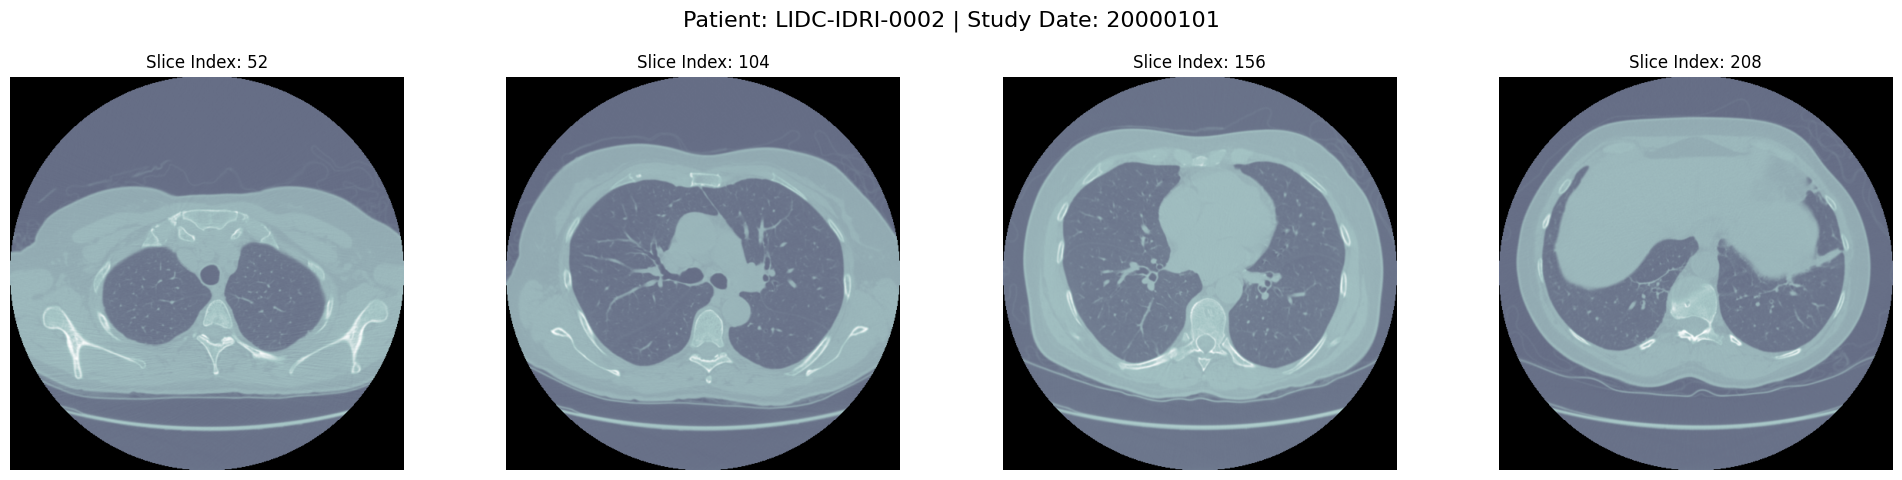

In [ ]:
import pydicom
import matplotlib.pyplot as plt
import os
import numpy as np

def visualize_ct_series(manifest_row):
    # 1. Validate modality and image count
    if manifest_row['modality'] != 'CT' or manifest_row['n_images'] <= 1:
        print(f"Skipping: Modality is {manifest_row['modality']} or n_images is {manifest_row['n_images']}.")
        return

    # 2. Load the series
    series_path = manifest_row['series_path']
    slice_files = [os.path.join(series_path, f) for f in os.listdir(series_path) if f.lower().endswith('.dcm')]

    slices = [pydicom.dcmread(f) for f in slice_files]

    # 3. Sort slices by InstanceNumber
    # Some files might not have InstanceNumber; handle gracefully by using 0 as default
    slices.sort(key=lambda x: int(x.InstanceNumber) if 'InstanceNumber' in x else 0)

    # 4. Pick 4 evenly spaced indices (0.2, 0.4, 0.6, 0.8)
    num_slices = len(slices)
    indices = [int(num_slices * factor) for factor in [0.2, 0.4, 0.6, 0.8]]

    # 5. Plotting
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    patient_id = manifest_row['patient_id']
    study_date = manifest_row['study_date']
    fig.suptitle(f"Patient: {patient_id} | Study Date: {study_date}", fontsize=16)

    for i, idx in enumerate(indices):
        ax = axes[i]
        slice_data = slices[idx]
        ax.imshow(slice_data.pixel_array, cmap=plt.cm.bone)
        ax.set_title(f"Slice Index: {idx}")
        ax.set_axis_off()

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Find the specific row for LIDC-IDRI-0002, 20000101, CT
target_row = dicom_manifest_df[
    (dicom_manifest_df['patient_id'] == 'LIDC-IDRI-0002') &
    (dicom_manifest_df['study_date'] == '20000101') &
    (dicom_manifest_df['modality'] == 'CT')
].iloc[0]

# Execute visualization
visualize_ct_series(target_row)

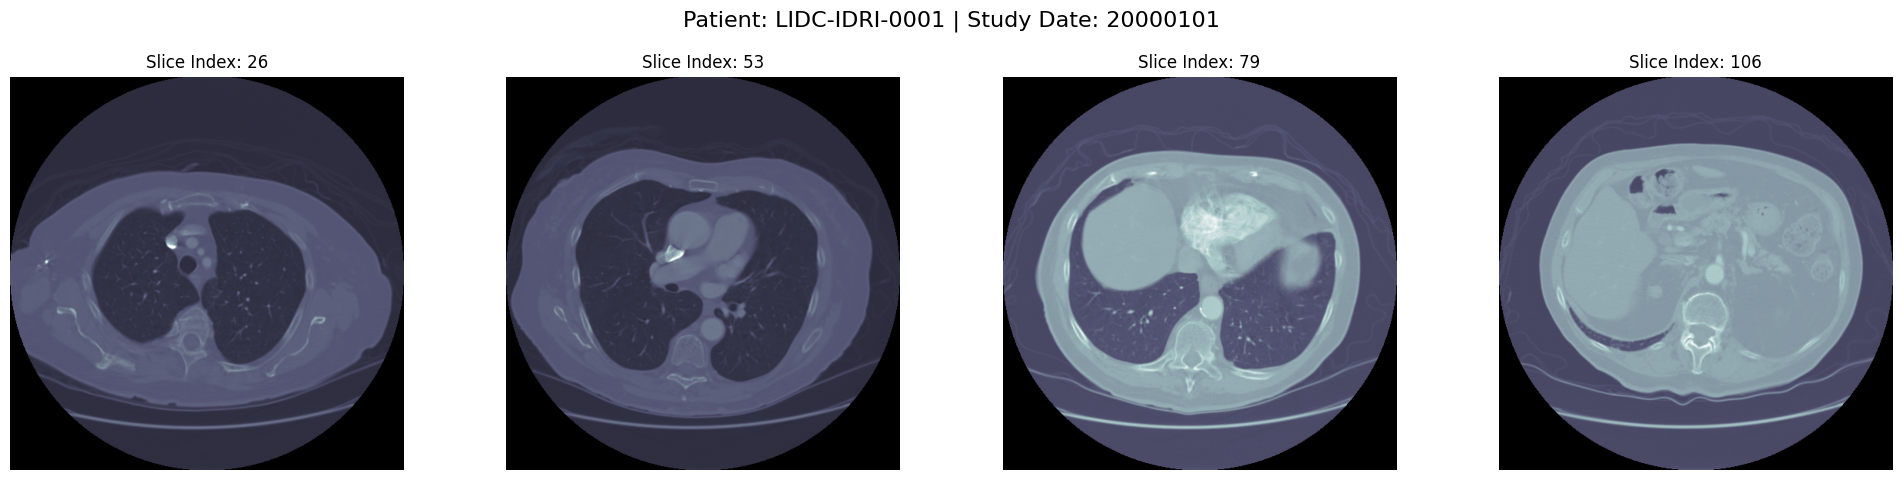

In [ ]:
# Find the specific row for LIDC-IDRI-0001, CT modality
target_row_0001 = dicom_manifest_df[
    (dicom_manifest_df['patient_id'] == 'LIDC-IDRI-0001') &
    (dicom_manifest_df['modality'] == 'CT')
].iloc[0]

# Execute visualization
visualize_ct_series(target_row_0001)